In [1]:
# In dev mode, run this
%load_ext autoreload
%autoreload 2

In [386]:
import numpy as np
import networkx as nx

import matplotlib as mpl
from matplotlib import pyplot as plt

import propnetscore.node_selection as ns
from propnetscore.plotting import plot_task, plot_task_aligned

## Example 12: Stochastic Block Model

In [22]:
G = nx.Graph()
G.add_nodes_from([i for i in range(15)])
G.add_edges_from([(0,1),(0,2),(0,4),(1,4),(2,4),(3,4),(4,5),(5,6),(5,9),(6,7),(6,9),(7,8),(8,9),(9,10),(10,11),(10,12),(11,12),(11,13),(12,14),(13,14)])

In [7]:
def connected_sbm(s, p, seed=None, max_tries=1000):
    """Generate a connected Stochastic Block Model graph by retrying until connected."""
    rng = np.random.default_rng(seed)
    for _ in range(max_tries):
        G = nx.stochastic_block_model(s, p, seed=int(rng.integers(1e9)))
        if nx.is_connected(G):
            return G
    raise RuntimeError(f"Failed to generate a connected graph after {max_tries} tries.")

In [8]:
s = [5, 7, 7]
p = [[0.5, 0.04, 0.03], [0.04, 0.4, 0.01], [0.03, 0.01, 0.4]]  # must be symmetric
G = connected_sbm(s, p, seed=42)
adjacency_matrix = nx.to_numpy_array(G, weight=None)
adjacency_matrix

array([[0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        1., 0., 0.],
       [0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [1., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 1., 1., 0., 1., 1., 0., 0., 0., 0.,
        0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0.

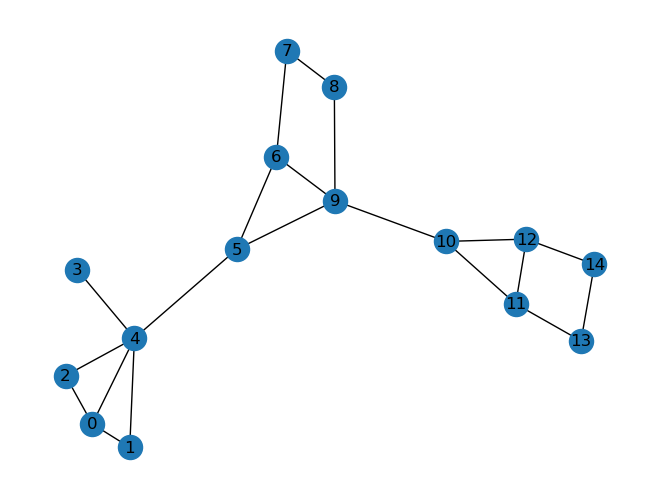

In [23]:
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)

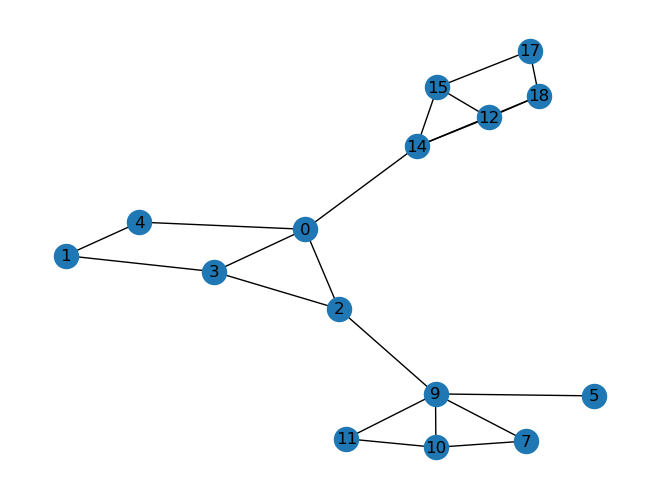

In [10]:
"""
# modify graph by hand
G.remove_node(6)
G.remove_node(8)
G.remove_node(13)
G.remove_node(16)
G.add_edge(2,9)
G.add_edge(0,14)
nx.draw(G, pos = nx.spring_layout(G), with_labels=True)
"""

In [99]:
# Task 12a

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.2
prediction[2] = 0.2
prediction[4] = 0.2
prediction[0] = 0.3
prediction[3] = 0.1

assert np.allclose(sum(prediction), 1)

task_12a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [100]:
# Task 12b (good prediction)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[9] = 0.1
prediction[2] = 0.2
prediction[5] = 0.2
prediction[4] = 0.3

assert np.allclose(sum(prediction), 1)

task_12b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [101]:
# Task 12c (even more miscalibrated)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[5] = 0.2
prediction[6] = 0.1
prediction[4] = 0.3
prediction[0] = 0.2
prediction[9] = 0.1
prediction[7] = 0.1

assert np.allclose(sum(prediction), 1)

task_12c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [102]:
# Task 12d (probability uniformly spread across correct cluster)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.2
prediction[1] = 0.2
prediction[2] = 0.2
prediction[3] = 0.2
prediction[4] = 0.2

assert np.allclose(sum(prediction), 1)

task_12d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [103]:
# Task 12e (probability uniformly spread across neighbouring cluster)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[5] = 0.2
prediction[6] = 0.2
prediction[7] = 0.2
prediction[8] = 0.2
prediction[9] = 0.2

assert np.allclose(sum(prediction), 1)

task_12e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [104]:
# Task 12f (probability uniformly spread across faraway cluster)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[10] = 0.2
prediction[11] = 0.2
prediction[12] = 0.2
prediction[13] = 0.2
prediction[14] = 0.2

assert np.allclose(sum(prediction), 1)

task_12f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [119]:
# Task 12g (probability in correct cluster, but on wrong nodes, sharper than previous version)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[3] = 0.4
prediction[1] = 0.2
prediction[2] = 0.2
prediction[4] = 0.2
assert np.allclose(sum(prediction), 1)

task_12g = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [128]:
# Task 12h (probability in correct cluster, but on wrong nodes)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.2
prediction[2] = 0.2
prediction[4] = 0.2
prediction[8] = 0.4

assert np.allclose(sum(prediction), 1)

task_12h = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [129]:
# Task 12i (atomic drops of probability in cluster centers)

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.2
prediction[2] = 0.2
prediction[4] = 0.2
prediction[11] = 0.4

assert np.allclose(sum(prediction), 1)

task_12i = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

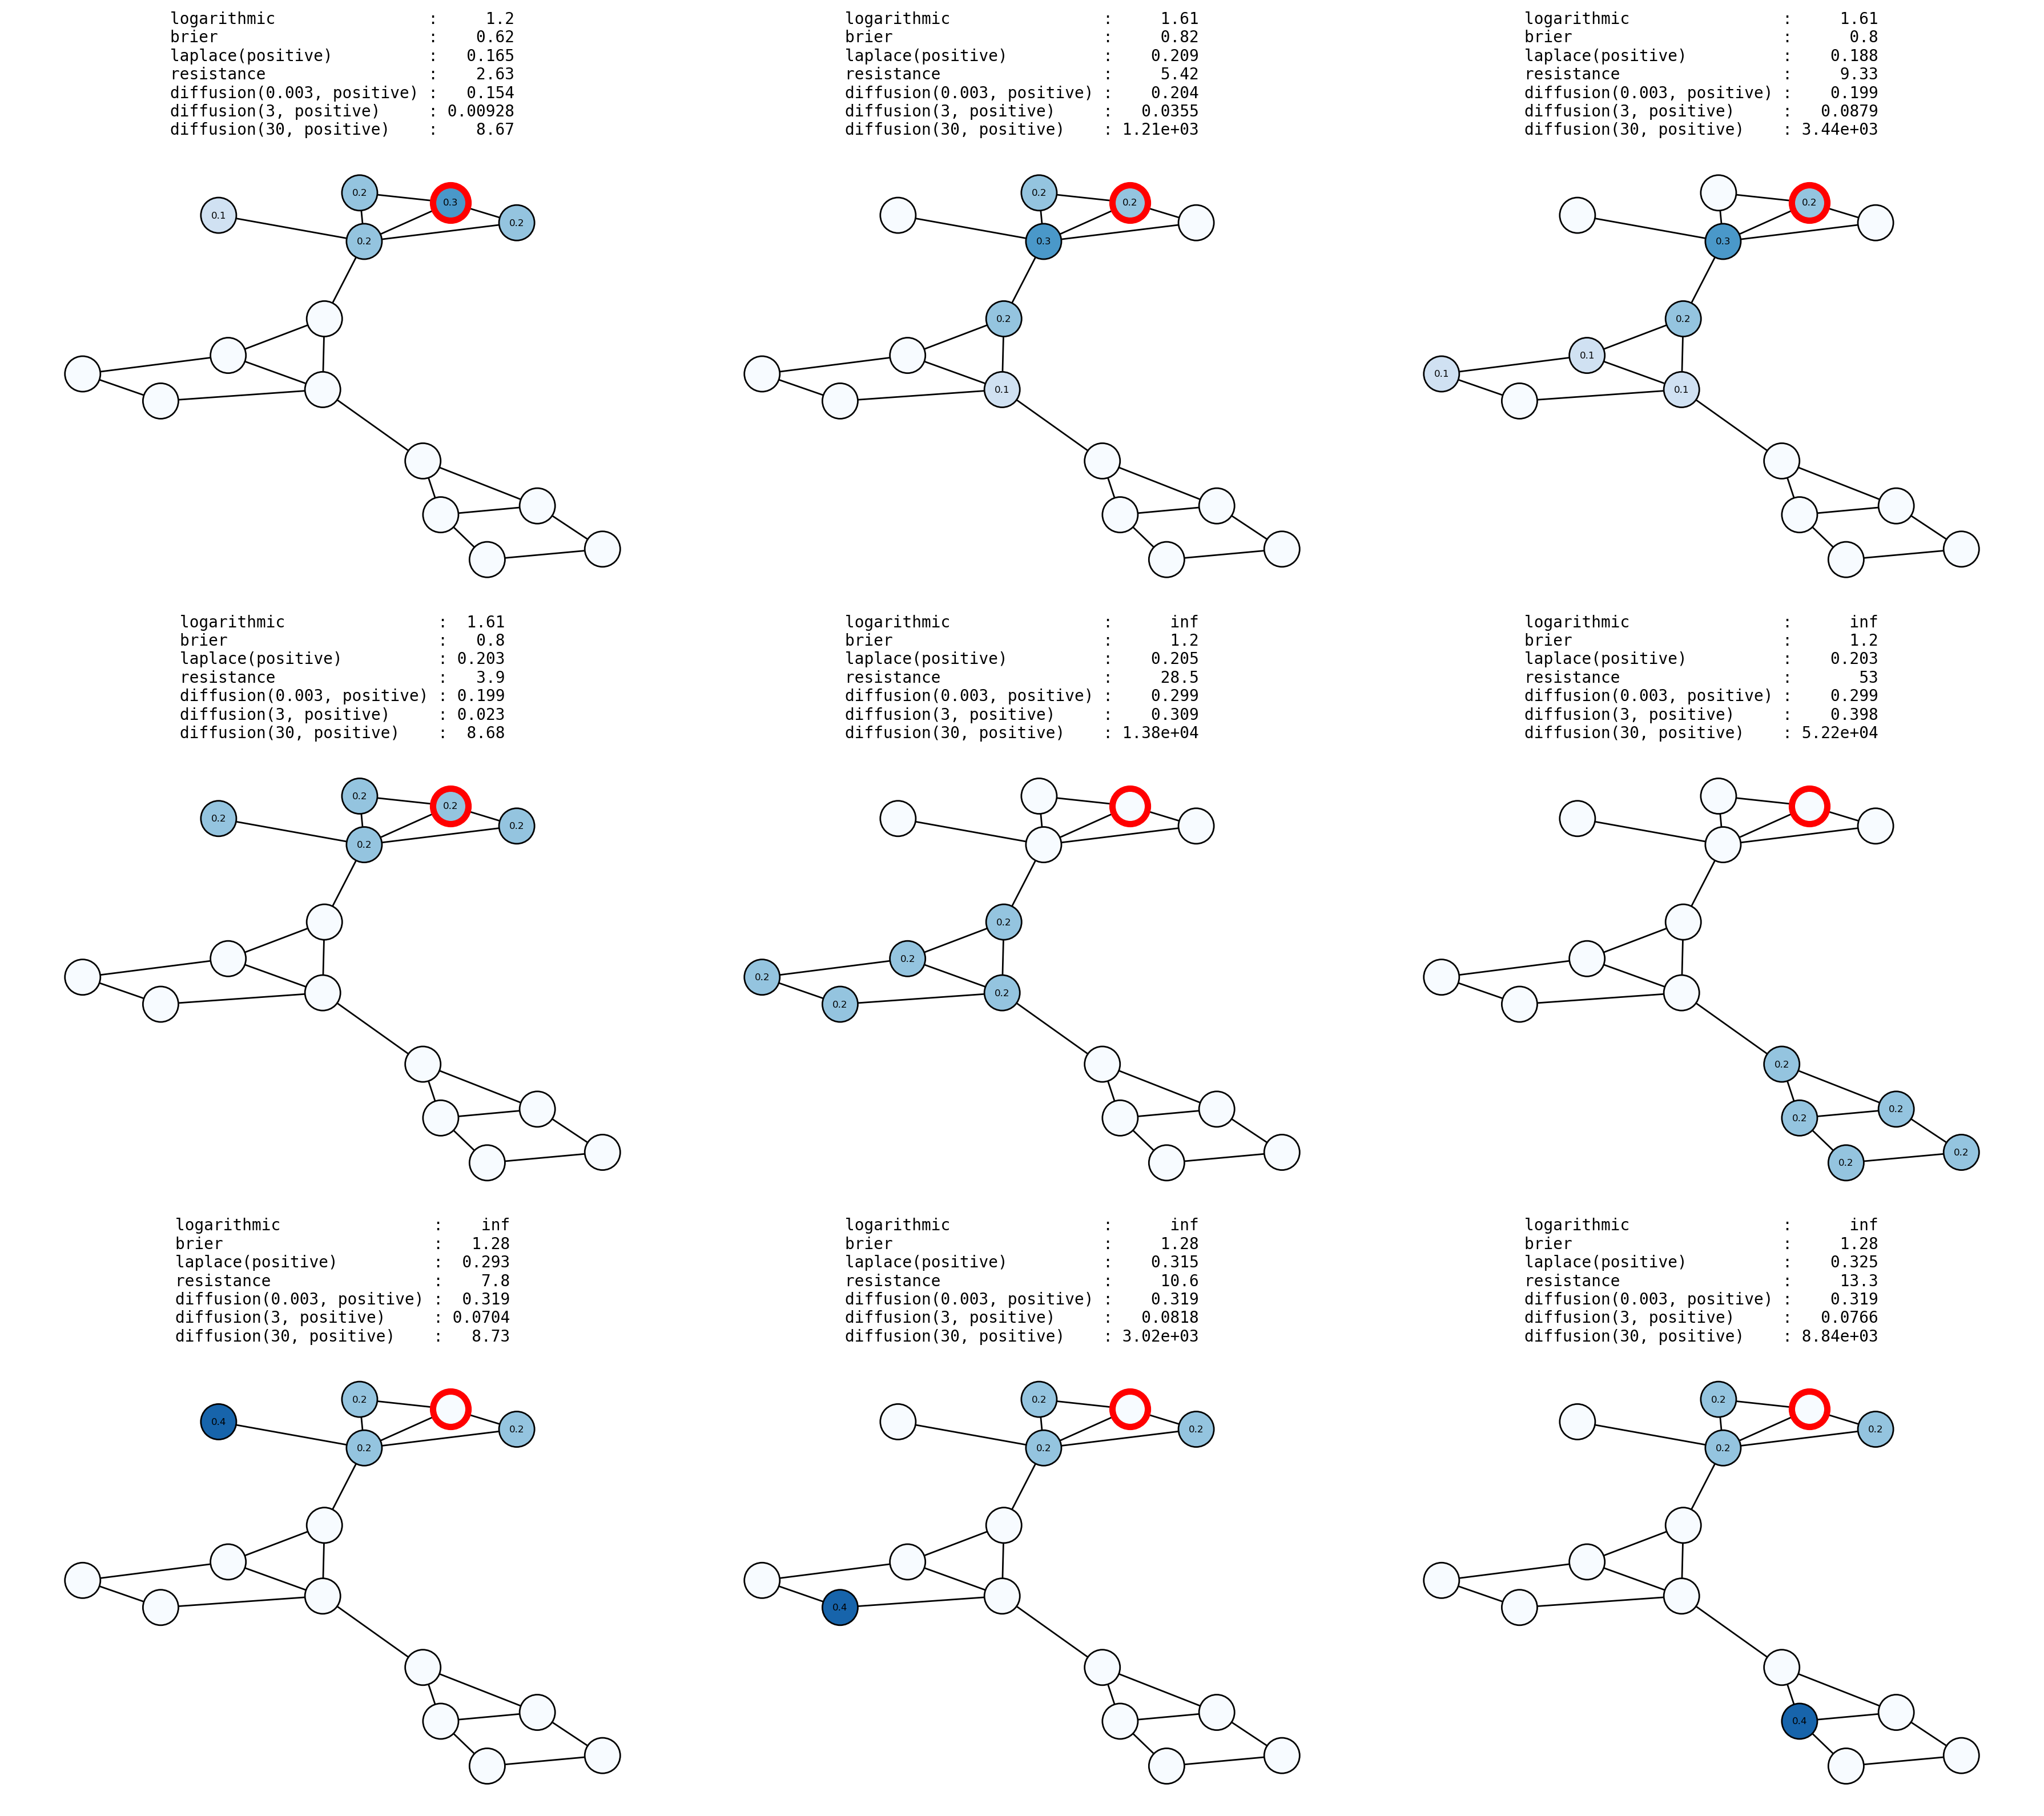

In [138]:
fig, axs = plt.subplots(3, 3, figsize=(18, 16), dpi=200)

for task, ax in zip([task_12a, task_12b, task_12c, task_12d, task_12e, task_12f, task_12g, task_12h, task_12i], axs.flatten()):
    plot_task(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels="prob", colorbar=False, contrast=1, max_prob=0.5, prob_color="Blues", true_color="red", 
        scores=[
            "logarithmic",
            "brier", 
            {"laplace": {"convention": "positive"}}, 
            "resistance", 
            {"diffusion": {"kappa2": 0.003, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 3, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 30, "convention": "positive"}}
        ], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()
plt.show()

## Simplified task

In [352]:
G = nx.Graph()
G.add_nodes_from([i for i in range(11)])
#G.add_edges_from([(0,1),(0,2),(0,4),(1,4),(2,4),(3,4),(4,5),(5,6),(5,9),(6,7),(6,9),(7,8),(8,9)])
G.add_edges_from([(0,1),(0,2),(0,4),(1,4),(2,4),(3,4),(4,5),(5,6),(5,9),(6,7),(6,9),(6,8),(8,9), (1,10),(4,10)])


In [364]:
G = nx.Graph()
G.add_nodes_from([i for i in range(10)])
G.add_edges_from([(0,1),(0,2),(0,4),(1,4),(2,4),(3,4),(4,5),(5,6),(5,9),(6,7),(6,9),(6,8),(8,9)])
G.remove_node(9)
G.add_edge(7,5)
G.add_node(9)
G.add_edges_from([(1,9),(4,9)])

In [365]:
# Task a

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.25
prediction[1] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25


assert np.allclose(sum(prediction), 1)

task_a = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [366]:
# Task b

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[3] = 0.25


assert np.allclose(sum(prediction), 1)

task_b = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [367]:
# Task c

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[0] = 0.25
prediction[5] = 0.25
prediction[4] = 0.25
prediction[3] = 0.25

assert np.allclose(sum(prediction), 1)

task_c = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [368]:
# Task d

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[3] = 0.25

assert np.allclose(sum(prediction), 1)

task_d = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [369]:
# Task e

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
prediction[1] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[5] = 0.25

assert np.allclose(sum(prediction), 1)

task_e = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

In [370]:
# Task f

# Ground truth
true_node = 0

# Prediction
prediction = np.zeros(len(G))
"""
prediction[7] = 0.25
prediction[6] = 0.25
prediction[9] = 0.25
prediction[5] = 0.25
"""
prediction[9] = 0.25
prediction[2] = 0.25
prediction[4] = 0.25
prediction[5] = 0.25

assert np.allclose(sum(prediction), 1)

task_f = ns.NodeSelectionTask(adjacency_matrix, prediction, true_node)

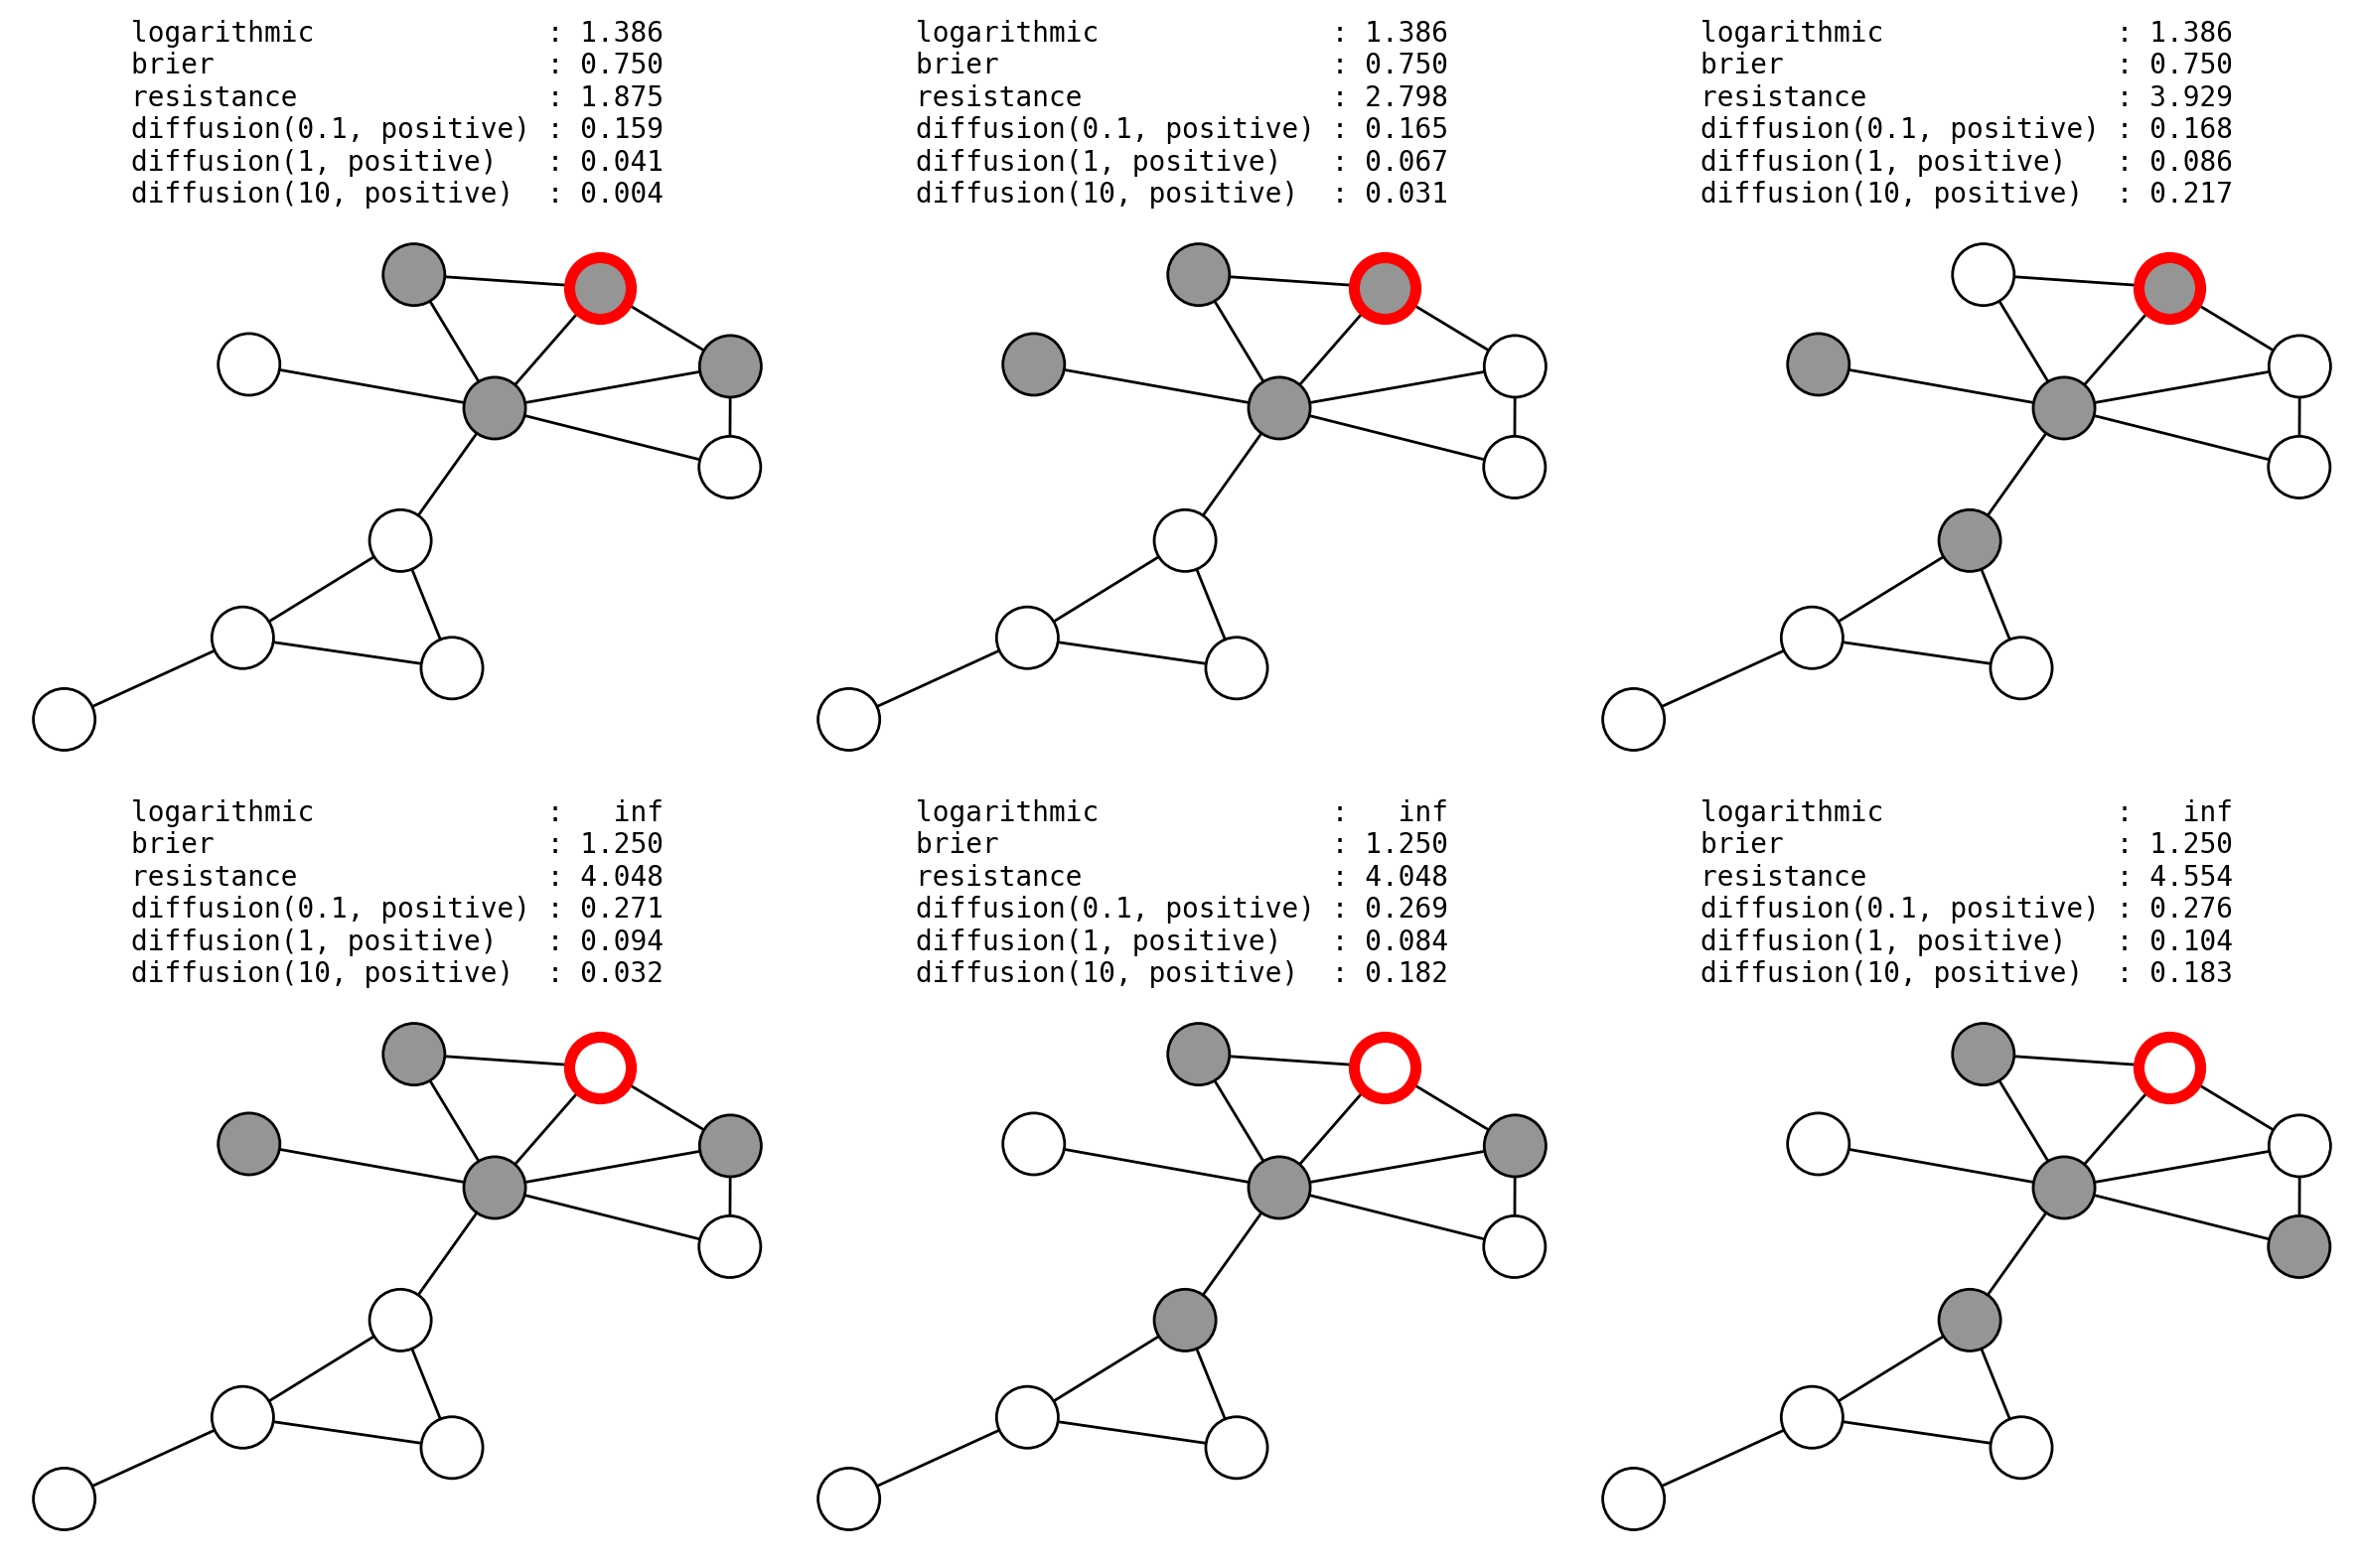

In [388]:
fig, axs = plt.subplots(2, 3, figsize=(12, 8), dpi=200)

for task, ax in zip([task_a, task_b, task_c, task_d, task_e, task_f], axs.flatten()):
    plot_task_aligned(
        ax, G, node_probs=task.node_probs, true_node=task.true_node, 
        labels=None, colorbar=False, contrast=1, max_prob=0.5, prob_color="Grays", true_color="red", 
        scores=[
            "logarithmic",
            "brier", 
            #{"laplace": {"convention": "positive"}}, 
            "resistance", 
            #{"diffusion": {"kappa2": 0.01, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 0.1, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 1, "convention": "positive"}}, 
            {"diffusion": {"kappa2": 10, "convention": "positive"}}
        ], 
        score_pos="top"
    )
    ax.set_axis_off()  # optional, already done in plot_task

plt.tight_layout()
plt.show()